In [102]:
import yfinance as yf
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from datetime import date

In [2]:
msft = yf.Ticker("MSFT")

In [3]:
expirations = msft.options
print("\n".join(expirations))

2026-02-27
2026-03-02
2026-03-04
2026-03-06
2026-03-13
2026-03-20
2026-03-27
2026-04-02
2026-04-17
2026-05-15
2026-06-18
2026-07-17
2026-08-21
2026-09-18
2026-10-16
2026-11-20
2026-12-18
2027-01-15
2027-03-19
2027-06-17
2027-12-17
2028-01-21
2028-06-16
2028-12-15


In [103]:
expiry = expirations[0]
T = (date.fromisoformat(expiry) - date.today()).days/365
r = 0.05
option_chain = msft.option_chain(expiry)

In [105]:
expiry, T, r

('2026-02-27', 0.0027397260273972603, 0.05)

In [30]:
current_price = msft.fast_info.last_price

In [39]:
calls = option_chain.calls
#filter calls to remove low volume
#calls = calls[calls["volume"] > 100]
#calls = calls[calls["strike"] < current_price*1.05]
#calls = calls[calls["strike"] > current_price*0.95]

puts = option_chain.puts

In [74]:
strikes = calls["strike"].values
call_prices = calls["lastPrice"].values
put_strikes = puts["strike"].values
put_prices = puts["lastPrice"].values
log_prices = np.log(call_prices)

weights = np.sqrt(calls["volume"].values) + 1e-5
weights[np.isnan(weights)] = 1e-5

In [70]:
puts

,contractSymbol,lastTradeDate,strike,lastPrice,bid,ask,change,percentChange,volume,openInterest,impliedVolatility,inTheMoney,contractSize,currency
0,MSFT260227P00270000,2026-02-25 18:20:30+00:00,270.0,0.01,0.00,0.01,0.0,0.0,1.0,123,1.687502,False,REGULAR,USD
1,MSFT260227P00280000,2026-02-25 19:47:18+00:00,280.0,0.01,0.00,0.01,0.0,0.0,1.0,382,1.531252,False,REGULAR,USD
2,MSFT260227P00290000,2026-02-24 18:10:45+00:00,290.0,0.02,0.00,0.01,0.0,0.0,2.0,51,1.375003,False,REGULAR,USD
3,MSFT260227P00300000,2026-02-25 15:30:24+00:00,300.0,0.01,0.00,0.01,0.0,0.0,14.0,223,1.250004,False,REGULAR,USD
4,MSFT260227P00310000,2026-02-25 14:47:32+00:00,310.0,0.01,0.00,0.01,0.0,0.0,1.0,867,1.125004,False,REGULAR,USD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,MSFT260227P00540000,2026-02-20 20:32:53+00:00,540.0,141.25,134.40,137.95,0.0,0.0,44.0,0,2.497074,True,REGULAR,USD
71,MSFT260227P00545000,2026-02-20 18:49:10+00:00,545.0,146.45,140.45,144.10,0.0,0.0,1.0,0,2.797122,True,REGULAR,USD
72,MSFT260227P00550000,2026-02-20 16:02:02+00:00,550.0,150.19,145.15,148.70,0.0,0.0,1.0,0,2.787601,True,REGULAR,USD
73,MSFT260227P00590000,2026-02-06 14:30:03+00:00,590.0,193.10,184.40,188.00,0.0,0.0,1.0,0,3.071291,True,REGULAR,USD


In [122]:
strike_space = np.linspace(strikes.min(), strikes.max(), 10000)

In [128]:
#call_prices_spline = scipy.interpolate.make_splrep(x=strikes, y=call_prices, w=weights, s=0.001, k=3)
#call_prices_spline = scipy.interpolate.PchipInterpolator(strikes, call_prices)
call_prices_spline = scipy.interpolate.make_interp_spline(x=strikes, y=call_prices, k=3)
#call_prices_spline = scipy.interpolate.CubicSpline(x=strikes, y=call_prices)

Text(0, 0.5, 'Call Price')

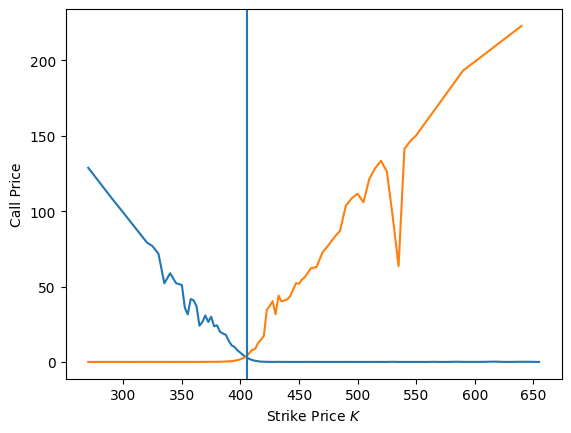

In [129]:
plt.plot(strikes, call_prices)
plt.plot(put_strikes, put_prices)
#plt.plot(strike_space, call_prices_spline(strike_space))
plt.axvline(current_price)
plt.xlabel("Strike Price $K$")
plt.ylabel("Call Price")

Breeden-Litzenberger: $\frac{\partial^2 C(K)}{\partial K^2} = e^{-rT}f_Q(K)$
- $K = $ Strike
- $C(K) = $ Call price as a function of strike
- $f_Q(K) = $ risk-neutral density at K
$$f_Q(K) = e^{rT}\frac{\partial^2 C(K)}{\partial K^2}$$

In [130]:
second_d = call_prices_spline.derivative(2)

In [131]:
T = 1
r = 0
risk_neutral_density = np.exp(r * T) * second_d(strike_space)

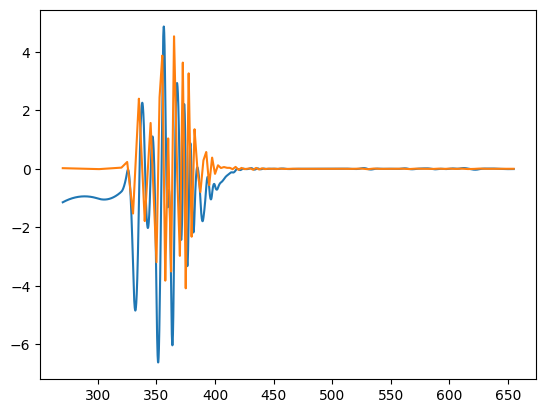

In [132]:
#plt.plot(strike_space, call_prices_spline(strike_space))
plt.plot(strike_space, call_prices_spline.derivative(1)(strike_space))
plt.plot(strike_space, call_prices_spline.derivative(2)(strike_space))

#plt.plot(scipy.differentiate.derivative

In [133]:
def exponential(x, a, b, c):
    return a * np.exp(-b * x) + c

In [134]:
def s_curve(x, L, k, x0):
    return (L/np.exp(k * (x-x0)) )

In [135]:
def bs_call(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * scipy.stats.norm.cdf(d1) - K * np.exp(-r * T) * scipy.stats.norm.cdf(d2)

In [136]:
params, covariance = scipy.optimize.curve_fit(lambda K,sigma: bs_call(current_price, K, T, r, sigma), strikes, call_prices, p0=[1])

In [143]:
sigma = params[0]

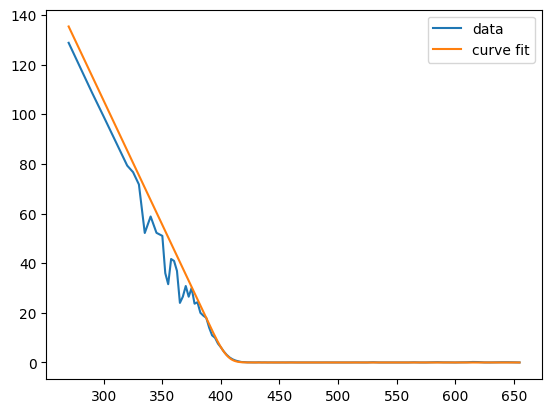

In [144]:
plt.plot(strikes, call_prices, label="data")
plt.plot(strike_space, bs_call(current_price, strike_space, T, r, sigma), label="curve fit")
plt.legend()

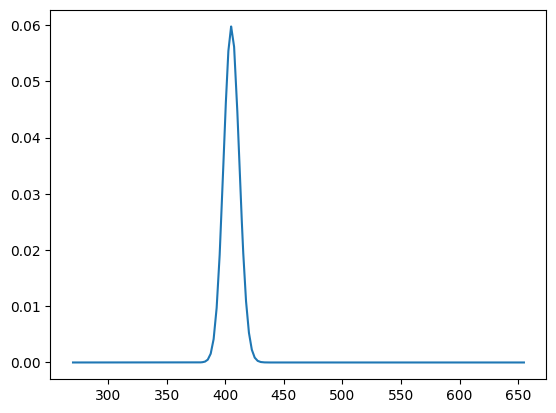

In [145]:
fit_spline = scipy.interpolate.make_interp_spline(strikes, bs_call(current_price, strikes, T, r, sigma))
second_derivative = fit_spline.derivative(2)
risk_neutral_density = second_derivative(strike_space) * np.exp(r * T)

#plt.plot(strikes, fit_spline.derivative(1)(strikes))
plt.plot(strike_space, risk_neutral_density)

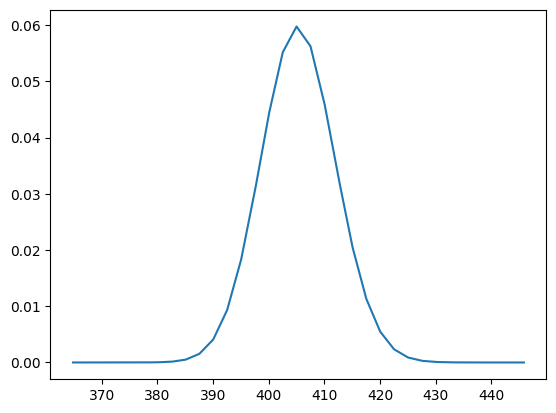

In [146]:
zoom_space = np.linspace(current_price*0.9, current_price*1.1, 10000)
plt.plot(zoom_space, second_derivative(zoom_space) * np.exp(r * T))

In [148]:
second_derivative.integrate(min(strikes), max(strikes))*np.exp(r * T)

np.float64(1.000000000000003)